# DATA ANALYTICS ML CHALLENGE / 2026-2
## Laboratorio 1. Modelos supervisados y métricas (Semana 12)

- Profesor: Elias Buitrago Bolivar  
- Estudiante: Carlos Alberto Mancilla Valle
- Universidad Central  
- Caso: Brazilian E-Commerce Public Dataset by Olist

Objetivo: construir un modelo base para anticipar entregas tardías a partir de datos de compras, productos, clientes, vendedores y pagos.

Las instrucciones de GitHub y entrega se encuentran en el documento técnico. Las secciones de carga y preparación se suministran resueltas; complete las cuatro actividades de modelado y evaluación.

### Configuración del Entorno Local (`src/iniciarEntorno`)

> **Nota importante:** Este bloque de código está diseñado para ejecutarse exclusivamente en **entornos locales** (como VS Code o Jupyter Notebook local).
>
> * **Prerrequisito Local:** Antes de ejecutar esta celda, ya debes haber creado y activado tu entorno virtual (`venv`) siguiendo los pasos descritos en el `README.md` en la carpeta `notebooks/README.md`, seleccionándolo como el *Kernel* activo del cuaderno.
> * **En Google Colab:** No es necesario ejecutar esta celda, ya que la nube de Colab gestiona sus propias dependencias preinstaladas.
> * **Función en local:** Carga el módulo personalizado `src/iniciarEntorno/gestor_dependencias.py` para verificar e instalar automáticamente cualquier librería faltante especificada en el archivo `requirements.txt` dentro de tu entorno virtual activo.

In [1]:
import sys
from pathlib import Path

# Detectar la raíz del proyecto buscando hacia arriba la carpeta que contiene 'src'
raiz = Path.cwd()
while raiz.name and not (raiz / 'src').exists():
    if raiz.parent == raiz:  # Llegó al directorio raíz del sistema sin encontrar src
        break
    raiz = raiz.parent

# Añadir la raíz del proyecto al sys.path
if str(raiz) not in sys.path:
    sys.path.append(str(raiz))

# Importación desde el módulo src.iniciarEntorno
from src.iniciarEntorno.gestor_dependencias import preparar_entorno

preparar_entorno()

    [Iniciando Entorno] Raíz detectada: C:\Users\yhonny\Desktop\Proyectos\data-analytics-ml-challenge
    [Entorno Listo] Todas las dependencias están al día


## 1. Carga de datos

Una observación del modelo corresponde a un pedido, aunque tenga varios productos y pagos. Se integrarán siete tablas del conjunto público de Olist.

In [2]:
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, mean_absolute_error)

print("Importaciones cargadas con éxito")

Importaciones cargadas con éxito


In [3]:
ORIGEN = ('https://raw.githubusercontent.com/spdrio/'
          'Brazilian-E-Commerce-Public-Dataset-by-Olist/'
          'fa0cc6d1aff713d3c8b9a1e633b56889881848bf/files')

pedidos = pd.read_csv(f'{ORIGEN}/olist_orders_dataset.csv')
items = pd.read_csv(f'{ORIGEN}/olist_order_items_dataset.csv')
productos = pd.read_csv(f'{ORIGEN}/olist_products_dataset.csv')
clientes = pd.read_csv(f'{ORIGEN}/olist_customers_dataset.csv')
vendedores = pd.read_csv(f'{ORIGEN}/olist_sellers_dataset.csv')
pagos = pd.read_csv(f'{ORIGEN}/olist_order_payments_dataset.csv')
categorias = pd.read_csv(f'{ORIGEN}/product_category_name_translation.csv')

print('Pedidos:', pedidos.shape)
print('Items:', items.shape)
print('Productos:', productos.shape)
print('Clientes:', clientes.shape)
print('Vendedores:', vendedores.shape)
print('Pagos:', pagos.shape)

Pedidos: (99441, 8)
Items: (112650, 7)
Productos: (32951, 9)
Clientes: (99441, 5)
Vendedores: (3095, 4)
Pagos: (103886, 5)


## 2. Preparación de variables

Un pedido puede contener varios ítems y pagos. Primero se resumen estas tablas por `order_id`, para evitar contar un mismo pedido varias veces. Las variables de destino se construyen después y no se incluyen entre los predictores.

In [4]:
# Información de los productos y vendedores incluidos en cada pedido.
items = items.merge(productos, on='product_id', how='left', validate='many_to_one')
items = items.merge(vendedores, on='seller_id', how='left', validate='many_to_one')
items = items.merge(categorias, on='product_category_name',
                    how='left', validate='many_to_one')

items['volumen_cm3'] = (items['product_length_cm'] * items['product_height_cm']
                       * items['product_width_cm'])
items['categoria'] = items['product_category_name_english'].fillna(
    items['product_category_name']).fillna('sin_categoria')

# Resumen de productos: una fila por pedido.
resumen_items = items.groupby('order_id', as_index=False).agg(
    valor_productos=('price', 'sum'),
    valor_flete=('freight_value', 'sum'),
    precio_maximo=('price', 'max'),
    cantidad_items=('order_item_id', 'count'),
    cantidad_productos=('product_id', 'nunique'),
    cantidad_vendedores=('seller_id', 'nunique'),
    peso_total_g=('product_weight_g', 'sum'),
    peso_maximo_g=('product_weight_g', 'max'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_promedio=('product_photos_qty', 'mean'),
    descripcion_promedio=('product_description_lenght', 'mean'),
    nombre_promedio=('product_name_lenght', 'mean'),
)

# Categoría y vendedor del producto de mayor precio del pedido.
principal = (items.sort_values(['order_id', 'price', 'order_item_id'],
                                ascending=[True, False, True])
             .drop_duplicates('order_id'))
principal = principal[['order_id', 'categoria', 'seller_state', 'seller_city']]
principal = principal.rename(columns={
    'categoria': 'categoria_principal',
    'seller_state': 'estado_vendedor',
    'seller_city': 'ciudad_vendedor'
})

In [5]:
# Los pagos también pueden aparecer en varias filas por pedido.
resumen_pagos = pagos.groupby('order_id', as_index=False).agg(
    numero_pagos=('payment_sequential', 'count'),
    cuotas_maximas=('payment_installments', 'max'),
    valor_pagado=('payment_value', 'sum'),
)

pago_principal = (pagos.sort_values(['order_id', 'payment_value'],
                                    ascending=[True, False])
                  .drop_duplicates('order_id'))
pago_principal = pago_principal[['order_id', 'payment_type']].rename(
    columns={'payment_type': 'tipo_pago_principal'})

# Integración de las tablas: una fila por pedido.
data = pedidos.merge(clientes[['customer_id', 'customer_state', 'customer_city']],
                     on='customer_id', how='inner', validate='one_to_one')
data = data.merge(resumen_items, on='order_id', how='inner', validate='one_to_one')
data = data.merge(principal, on='order_id', how='left', validate='one_to_one')
data = data.merge(resumen_pagos, on='order_id', how='left', validate='one_to_one')
data = data.merge(pago_principal, on='order_id', how='left', validate='one_to_one')

assert data['order_id'].is_unique, 'Hay pedidos duplicados después de las uniones.'
print('Pedidos integrados:', len(data))

Pedidos integrados: 98666


In [6]:
# Se consideran pedidos entregados con fechas completas y coherentes.
fechas = ['order_purchase_timestamp', 'order_estimated_delivery_date',
          'order_delivered_customer_date']
for columna in fechas:
    data[columna] = pd.to_datetime(data[columna], errors='coerce')

data = data.loc[data['order_status'] == 'delivered'].dropna(subset=fechas).copy()
compra = data['order_purchase_timestamp'].dt.normalize()
prevista = data['order_estimated_delivery_date'].dt.normalize()
real = data['order_delivered_customer_date'].dt.normalize()

data['dias_prometidos'] = (prevista - compra).dt.days
data['dias_entrega'] = (real - compra).dt.days
data['is_late'] = (real > prevista).astype(int)
data['mes_compra'] = compra.dt.month
data['dia_semana_compra'] = compra.dt.dayofweek
data['dia_mes_compra'] = compra.dt.day
data['hora_compra'] = data['order_purchase_timestamp'].dt.hour
data['compra_fin_semana'] = (data['dia_semana_compra'] >= 5).astype(int)

data['vendedor_mismo_estado'] = (
    data['customer_state'] == data['estado_vendedor']).astype(int)
data['vendedor_misma_ciudad'] = (
    data['vendedor_mismo_estado'].eq(1) &
    data['customer_city'].str.lower().eq(data['ciudad_vendedor'].str.lower())
).astype(int)
data['proporcion_flete'] = data['valor_flete'] / (
    data['valor_productos'] + data['valor_flete']).replace(0, np.nan)

data = data.loc[(data['dias_prometidos'] >= 0) &
                (data['dias_entrega'] >= 0)].copy()
data = data.sort_values('order_id').reset_index(drop=True)

print('Pedidos disponibles:', len(data))
print('Entregas tardías:', round(100 * data['is_late'].mean(), 2), '%')

Pedidos disponibles: 96470
Entregas tardías: 6.77 %


### Variables del modelo

Se utilizarán datos que razonablemente están disponibles al cierre de la compra: plazo prometido, calendario, contenido del pedido, dimensiones de los productos, ubicación y medio de pago. Las fechas reales de envío y entrega, y las reseñas posteriores, quedan excluidas de las variables predictoras.

La lista de variables y sus tablas de origen se encuentra en el diccionario técnico anexo.

In [7]:
columnas_numericas = [
    'dias_prometidos', 'mes_compra', 'dia_semana_compra',
    'dia_mes_compra', 'hora_compra', 'compra_fin_semana',
    'valor_productos', 'valor_flete', 'precio_maximo',
    'cantidad_items', 'cantidad_productos', 'cantidad_vendedores',
    'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3',
    'fotos_promedio', 'descripcion_promedio', 'nombre_promedio',
    'numero_pagos', 'cuotas_maximas', 'valor_pagado',
    'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete'
]
columnas_categoricas = [
    'customer_state', 'estado_vendedor',
    'categoria_principal', 'tipo_pago_principal'
]
columnas = columnas_numericas + columnas_categoricas

assert data['order_id'].is_unique
assert len(data) >= 35000
print('Variables predictoras:', len(columnas))
print('Numéricas:', len(columnas_numericas), '| Categóricas:', len(columnas_categoricas))

Variables predictoras: 28
Numéricas: 24 | Categóricas: 4


### Muestra individual

Cada estudiante utilizará 35.000 pedidos, seleccionados a partir del ID numérico entregado por el profesor (por ejemplo, ID 01). El mismo ID genera siempre la misma muestra y las mismas particiones.

Se utilizarán 24.500 pedidos para entrenar, 5.250 para validar y 5.250 para la prueba final. Durante las semanas 12 a 15 no se utilizarán los datos de prueba para elegir modelos.

En la siguiente celda cambie `ID_ESTUDIANTE` por el número asignado por el profesor. Por ejemplo, el ID 01 se escribe como `1`.


In [8]:
# Escriba el ID que le asignó el profesor (01 se escribe 1).
ID_ESTUDIANTE = 19
assert isinstance(ID_ESTUDIANTE, int) and 1 <= ID_ESTUDIANTE <= 30, (
    'El ID debe ser un número entero entre 1 y 30.')

semilla = 1000 + ID_ESTUDIANTE
identificador = f'{ID_ESTUDIANTE:02d}'

muestra, _ = train_test_split(data, train_size=35000,
                             random_state=semilla, stratify=data['is_late'])
muestra = muestra.sort_values('order_id').reset_index(drop=True)

train, temporal = train_test_split(muestra, test_size=0.30,
                                  random_state=semilla, stratify=muestra['is_late'])
valid, test = train_test_split(temporal, test_size=0.50,
                               random_state=semilla, stratify=temporal['is_late'])

X_train, y_train = train[columnas], train['is_late']
X_valid, y_valid = valid[columnas], valid['is_late']

huella_muestra = hashlib.sha256('|'.join(muestra['order_id']).encode()).hexdigest()[:12]
print('Estudiante ID:', identificador, '| Semilla:', semilla)
print('Muestra:', len(muestra), '| Train:', len(train),
      '| Valid:', len(valid), '| Test:', len(test))
print('Huella de muestra:', huella_muestra)

Estudiante ID: 19 | Semilla: 1019
Muestra: 35000 | Train: 24500 | Valid: 5250 | Test: 5250
Huella de muestra: 120d6b36c5fa


## 3. Modelo de referencia y clasificación

Las variables numéricas se imputan y escalan; las categóricas se transforman con *One-Hot Encoding*. Estas transformaciones se ajustan únicamente con los datos de entrenamiento, dentro del `Pipeline`.

In [9]:
preprocesamiento = ColumnTransformer([
    ('numericas', make_pipeline(SimpleImputer(strategy='median'),
                               StandardScaler()), columnas_numericas),
    ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                 OneHotEncoder(handle_unknown='ignore')),
     columnas_categoricas)
])

referencia = DummyClassifier(strategy='most_frequent')
referencia.fit(X_train, y_train)
pred_ref = referencia.predict(X_valid)

print('Accuracy referencia:', round(accuracy_score(y_valid, pred_ref), 3))
print('F1 referencia:', round(f1_score(y_valid, pred_ref, zero_division=0), 3))

Accuracy referencia: 0.932
F1 referencia: 0.0


### Actividad 1. Entrenamiento

Complete el entrenamiento de la regresión logística usando `preprocesamiento`. Pruebe `class_weight=None` o `'balanced'`, y explique su elección en la sección de interpretación. Conserve las variables `modelo` y `pred`.

En el estimador utilice `class_weight=peso_clases` y `max_iter=1000` como límite de iteraciones. Si aparece una advertencia de convergencia, revise el entrenamiento.


In [10]:
"""
Actividad 1: Entrenamiento del modelo de regresion logistica base.

Este bloque construye un pipeline de scikit-learn que integra el preprocesamiento
previamente definido con una Regresion Logistica. Se entrena el modelo sobre el
conjunto de entrenamiento (X_train, y_train) y se generan las predicciones
binarias sobre el conjunto de validacion (X_valid).
"""

# Configuración del manejo de desbalance de clases.
# 'balanced' ajusta los pesos de la función de pérdida de forma inversamente
# proporcional a las frecuencias de clase en los datos de entrenamiento.
peso_clases = 'balanced'

# Construcción del pipeline modular.
modelo = make_pipeline(
    preprocesamiento,
    LogisticRegression(
        class_weight=peso_clases,  # Manejo del desbalance de clases
        max_iter=1000,             # Límite máximo de iteraciones para convergencia
        random_state=semilla       # Semilla para asegurar reproducibilidad
    )
)

# Ajuste del pipeline completo con los datos de entrenamiento.
modelo.fit(X_train, y_train)

# Generación de predicciones binarias para el conjunto de validación.
pred = modelo.predict(X_valid)

print("Modelo ajustado y predicciones generadas correctamente.")

Modelo ajustado y predicciones generadas correctamente.


## 4. Evaluación

### Actividad 2. Métricas

Calcule Accuracy, Precision, Recall, F1, ROC-AUC y Average Precision (AP) en validación. Para las métricas AUC use las probabilidades que estima el modelo.

In [11]:
"""
Actividad 2: Cálculo de métricas de evaluación y probabilidades en validación.

Se estiman las probabilidades pertenecientes a la clase positiva (entregas tardías)
y se evalúan las métricas de rendimiento: Accuracy, Precision, Recall, F1-Score,
ROC-AUC y Average Precision (AP). Adicionalmente, se despliega la matriz de confusión.
"""

# Extracción de probabilidades para la clase positiva (1: entrega tardía)
proba = modelo.predict_proba(X_valid)[:, 1]

# Cálculo de las métricas de evaluación solicitadas
medidas = {
    'accuracy': accuracy_score(y_valid, pred),
    'precision': precision_score(y_valid, pred, zero_division=0),
    'recall': recall_score(y_valid, pred, zero_division=0),
    'f1': f1_score(y_valid, pred, zero_division=0),
    'roc_auc': roc_auc_score(y_valid, proba),
    'ap': average_precision_score(y_valid, proba),
}

# Impresión formativa de métricas
print("    Métricas en Validación\n")
for nombre, valor in medidas.items():
    print(f"{nombre.upper():<10}: {valor:.4f}")

# Matriz de confusión
print("\n    Matriz de Confusión\n")
cm = confusion_matrix(y_valid, pred)
print(cm)

    Métricas en Validación

ACCURACY  : 0.6547
PRECISION : 0.1183
RECALL    : 0.6366
F1        : 0.1996
ROC_AUC   : 0.6925
AP        : 0.1402

    Matriz de Confusión

[[3211 1684]
 [ 129  226]]


#### Comparación de `class_weight` (apoyo a la Actividad 1)

Se entrena una segunda regresión logística con `class_weight=None` solo para justificar la elección de `'balanced'` con resultados en validación. El modelo oficial sigue siendo `modelo`.

In [24]:
"""
Comparación de class_weight: None vs 'balanced' (solo en validación).

Se entrena una variable auxiliar (modelo_none) para no modificar 'modelo',
'pred', 'proba' ni 'medidas', que se usan en la autoverificación y en el reporte.
"""
from sklearn.base import clone

# Modelo alternativo sin ponderar las clases
modelo_none = make_pipeline(
    clone(preprocesamiento),
    LogisticRegression(class_weight=None, max_iter=1000, random_state=semilla)
)
modelo_none.fit(X_train, y_train)

pred_none = modelo_none.predict(X_valid)
proba_none = modelo_none.predict_proba(X_valid)[:, 1]

def resumen(nombre, y_real, y_pred, y_proba):
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred).ravel()
    return {
        'class_weight': nombre,
        'accuracy': accuracy_score(y_real, y_pred),
        'precision': precision_score(y_real, y_pred, zero_division=0),
        'recall': recall_score(y_real, y_pred, zero_division=0),
        'f1': f1_score(y_real, y_pred, zero_division=0),
        'roc_auc': roc_auc_score(y_real, y_proba),
        'ap': average_precision_score(y_real, y_proba),
        'FP': fp,
        'FN': fn,
        'costo_R$': 8 * fp + 35 * fn,
    }

# Probabilidades del Dummy (constantes: siempre predice la clase mayoritaria)
proba_ref = referencia.predict_proba(X_valid)[:, 1]

comparacion = pd.DataFrame([
    resumen('Dummy (referencia)', y_valid, pred_ref, proba_ref),
    resumen('None', y_valid, pred_none, proba_none),
    resumen('balanced', y_valid, pred, proba),
]).set_index('class_weight')

print(comparacion.round(4).to_string())

                    accuracy  precision  recall      f1  roc_auc      ap    FP   FN  costo_R$
class_weight                                                                                 
Dummy (referencia)    0.9324     0.0000  0.0000  0.0000   0.5000  0.0676     0  355     12425
None                  0.9324     0.0000  0.0000  0.0000   0.6913  0.1459     0  355     12425
balanced              0.6547     0.1183  0.6366  0.1996   0.6925  0.1402  1684  129     17987


### Actividad 3. Errores por segmento

Compare la tasa de error por mes de compra y estado del cliente. Muestre tanto el porcentaje de error como la cantidad de pedidos de cada segmento.

In [12]:
"""
Actividad 3: Análisis de errores por segmento.

Se evalúa la tasa de error del modelo agrupada por el mes de compra y el estado
del cliente. Se calcula el número total de pedidos, la cantidad de errores cometidos
y el porcentaje de error para cada segmento.
"""

assert pred is not None, 'Complete primero la Actividad 1 (variable pred).'

# Preparación del DataFrame de análisis con las etiquetas reales y predichas
analisis = valid.copy()
analisis['pred'] = pred
analisis['error'] = (analisis['is_late'] != analisis['pred']).astype(int)

# Agrupación por mes de compra
error_por_mes = analisis.groupby('mes_compra').agg(
    total_pedidos=('error', 'count'),
    cantidad_errores=('error', 'sum'),
    tasa_error=('error', 'mean')
).reset_index()

# Agrupación por estado del cliente
error_por_estado = analisis.groupby('customer_state').agg(
    total_pedidos=('error', 'count'),
    cantidad_errores=('error', 'sum'),
    tasa_error=('error', 'mean')
).sort_values(by='total_pedidos', ascending=False).reset_index()

# Visualización de los resultados
print("    Error por Mes de Compra\n")
print(error_por_mes)

print("\n    Top 10 Estados de Clientes con Mayor Volumen y sus Errores\n")
print(error_por_estado.head(10))

    Error por Mes de Compra

    mes_compra  total_pedidos  cantidad_errores  tasa_error
0            1            413               146    0.353511
1            2            442               172    0.389140
2            3            511               226    0.442270
3            4            523               161    0.307839
4            5            595               212    0.356303
5            6            506               112    0.221344
6            7            576               223    0.387153
7            8            574               281    0.489547
8            9            210                80    0.380952
9           10            227                66    0.290749
10          11            362                87    0.240331
11          12            311                47    0.151125

    Top 10 Estados de Clientes con Mayor Volumen y sus Errores

  customer_state  total_pedidos  cantidad_errores  tasa_error
0             SP           2238               411    0.183646
1 

### Actividad 4. Costo empresarial

Para el ejercicio, suponga un costo de R$ 8 por falso positivo y R$ 35 por falso negativo. Calcule el costo total de los errores en validación.

In [13]:
"""
Actividad 4: Cálculo del costo financiero empresarial de los errores.

Se obtiene la matriz de confusión para extraer los Falsos Positivos (FP) y
los Falsos Negativos (FN). Se asigna un costo penalizador de R$ 8 por FP
(alerta de retraso innecesaria) y R$ 35 por FN (retraso no detectado a tiempo),
calculando el impacto económico total.
"""

# Extracción de Falsos Positivos (FP) y Falsos Negativos (FN) desde la matriz
tn_ver, fp_ver, fn_ver, tp_ver = confusion_matrix(y_valid, pred).ravel()

# Cálculo del costo total acumulado
costo_fp_fn = (8 * fp_ver) + (35 * fn_ver)

# Despliegue de resultados financieros
print("    Análisis de Costo Empresarial\n")
print(f"- Falsos Positivos (FP): {fp_ver} (Costo parcial: R$ {fp_ver * 8:,.2f})")
print(f"- Falsos Negativos (FN): {fn_ver} (Costo parcial: R$ {fn_ver * 35:,.2f})")
print(f"- Costo Total Estimado : R$ {costo_fp_fn:,.2f}")

    Análisis de Costo Empresarial

- Falsos Positivos (FP): 1684 (Costo parcial: R$ 13,472.00)
- Falsos Negativos (FN): 129 (Costo parcial: R$ 4,515.00)
- Costo Total Estimado : R$ 17,987.00


### Autoverificación

Ejecute estas comprobaciones después de completar las actividades.

In [14]:
assert len(muestra) == 35000, 'La muestra debe tener 35000 pedidos.'
assert (len(train), len(valid), len(test)) == (24500, 5250, 5250), (
    'Particiones esperadas: 24500 / 5250 / 5250. Revise la celda de muestra.')
assert set(train['order_id']).isdisjoint(valid['order_id']), 'Train y valid comparten pedidos.'
assert set(train['order_id']).isdisjoint(test['order_id']), 'Train y test comparten pedidos.'
assert set(valid['order_id']).isdisjoint(test['order_id']), 'Valid y test comparten pedidos.'

assert modelo is not None and pred is not None, 'Complete la Actividad 1.'
assert len(pred) == len(y_valid), 'pred debe tener 5250 predicciones de validación.'
assert set(np.unique(np.asarray(pred))).issubset({0, 1}), 'pred debe contener solo clases 0 y 1.'
assert np.array_equal(np.asarray(pred), modelo.predict(X_valid)), (
    'pred no coincide con modelo.predict(X_valid). Verifique que utilizó X_valid.')

assert all(isinstance(v, (float, int, np.number)) for v in medidas.values()), (
    'Complete las métricas de la Actividad 2.')
assert proba is not None, 'Complete la Actividad 2: calcule las probabilidades.'
assert np.asarray(proba).ndim == 1 and len(proba) == len(y_valid), (
    'proba debe contener una probabilidad por pedido de validación.')
assert np.allclose(proba, modelo.predict_proba(X_valid)[:, 1]), (
    'proba no coincide con modelo.predict_proba(X_valid)[:, 1].')
assert np.isclose(medidas['f1'], f1_score(y_valid, pred, zero_division=0)), (
    "medidas['f1'] no coincide. Use f1_score(y_valid, pred, zero_division=0).")
assert np.isclose(medidas['ap'], average_precision_score(y_valid, proba)), (
    "medidas['ap'] no coincide. Use average_precision_score(y_valid, proba).")
assert np.isclose(medidas['roc_auc'], roc_auc_score(y_valid, proba)), (
    "medidas['roc_auc'] no coincide. Use roc_auc_score(y_valid, proba).")

assert isinstance(costo_fp_fn, (int, float, np.number)), (
    'Complete la Actividad 4: costo_fp_fn debe ser numérico (8*FP + 35*FN).')
_, fp_ver, fn_ver, _ = confusion_matrix(y_valid, pred).ravel()
assert np.isclose(costo_fp_fn, 8 * fp_ver + 35 * fn_ver), (
    'El costo no coincide con 8*FP + 35*FN. Revise la Actividad 4.')
print('Autoverificación superada.')

Autoverificación superada.


## 5. Ejemplo guiado de regresión

Con los mismos predictores, estime la duración total de la entrega en días usando `Ridge` y evalúe el error absoluto medio (MAE).

In [15]:
from sklearn.base import clone

# Cada modelo recibe una copia independiente del preprocesamiento.
modelo_reg = make_pipeline(clone(preprocesamiento), Ridge(solver='lsqr'))
modelo_reg.fit(X_train, train['dias_entrega'])
pred_dias = modelo_reg.predict(X_valid)
mae = mean_absolute_error(valid['dias_entrega'], pred_dias)
print('MAE regresión:', round(mae, 2), 'días')

MAE regresión: 5.21 días


## 6. Interpretación de negocio

1. Compare la regresión logística con el modelo de referencia utilizando Accuracy, Recall y F1. Justifique su elección de `class_weight`.

Respuesta:

Resultados en validación (5.250 pedidos, 355 tardíos reales, 6,8 %):

| Métrica | Referencia (Dummy) | LogReg `class_weight=None` | LogReg `class_weight='balanced'` |
|---|---|---|---|
| Accuracy | 0.932 | 0.932 | 0.655 |
| Precision | 0.000 | 0.000 | 0.118 |
| Recall | 0.000 | 0.000 | 0.637 |
| F1 | 0.000 | 0.000 | 0.200 |
| ROC-AUC | 0.500 | 0.691 | 0.693 |
| AP | 0.068 | 0.146 | 0.140 |
| Costo (R$ 8·FP + 35·FN) | 12.425 | 12.425 | 17.987 |

* **Modelo de referencia:** su Accuracy de 0.932 solo refleja que el 93,2 % de los pedidos llega a tiempo. Como nunca predice un retraso, su Recall y su F1 son 0 y no detecta ningún pedido que requiera atención. Su ROC-AUC de 0.500 y su AP de 0.068 (igual a la proporción de retrasos) marcan el nivel de un modelo sin información: la regresión logística los supera, con un ROC-AUC de 0.693 y un AP de 0.140, aproximadamente el doble de la prevalencia.
* **`class_weight=None`:** con el umbral por defecto, el modelo no predice ningún retraso (0 FP y 355 FN). Obtiene el mismo Accuracy, Recall y F1 que la referencia, por lo que no aporta valor operativo, aunque su ROC-AUC (0.691) muestra que sí hay señal en los datos.
* **`class_weight='balanced'`:** el Accuracy baja a 0.655, pero el Recall sube a 0.637 (detecta 226 de los 355 retrasos) y el F1 pasa de 0 a 0.200. La Precision es de solo 0.118: emite 1.910 alertas (36,4 % de los pedidos) y apenas 226 son retrasos reales.

**Justificación de `class_weight='balanced'`:** con solo 6,8 % de pedidos tardíos, el modelo sin ponderar queda en la clase mayoritaria y no detecta nada, mientras que `'balanced'` penaliza más los errores sobre la clase minoritaria y logra alertas con un Recall de 0.637. Elegí `'balanced'` por su capacidad de detección, no por costo: con los valores del ejercicio, `None` resulta más barato (R$ 12.425 vs R$ 17.987) únicamente porque equivale a no alertar nunca. Al no predecir ningún retraso, comete 0 falsos positivos y los 355 retrasos reales quedan como falsos negativos, de modo que su costo es 355 × R$ 35 = R$ 12.425, es decir, acepta todos los retrasos sin intervenir. El ROC-AUC y el AP son casi iguales en ambos modelos, así que la capacidad de ordenar los pedidos por riesgo es similar; la diferencia está en el umbral efectivo de decisión. Por eso, en la semana 13 el umbral y las variables serán la palanca de mejora, no solo el `class_weight`.

2. Analice qué tipo de pedidos presenta mayor error según los segmentos estudiados. ¿Cómo se relaciona esto con el costo de falsos positivos y falsos negativos?

Respuesta:

El error del modelo no es uniforme. En validación hay 1.813 errores (1.684 FP y 129 FN), y se concentran en ciertos segmentos.

* **Por estado del cliente:** São Paulo, que concentra 2.238 pedidos (42,6 % de la validación), tiene una tasa de error de 18,4 %. En cambio, RJ (701 pedidos) tiene 65,5 %, BA (175 pedidos) 73,1 %, SC (190 pedidos) 62,1 % y ES (108 pedidos) 57,4 %. Solo RJ aporta 459 errores, más que SP (411), con tres veces menos pedidos. En conjunto, RJ, BA y SC representan el 20,3 % de los pedidos pero el 38,9 % de los errores. MG (23,5 %), PR (21,5 %) y GO (25,5 %) se comportan de forma similar a SP.
* **Por mes de compra:** la tasa de error es más alta en agosto (49,0 %), marzo (44,2 %), febrero (38,9 %) y julio (38,7 %), y más baja en diciembre (15,1 %), junio (22,1 %) y noviembre (24,0 %). Septiembre y octubre tienen pocos pedidos (210 y 227), por lo que sus tasas son menos confiables. Los picos no coinciden con la temporada festiva, así que el patrón mensual parece más una variación del comportamiento logístico de cada periodo que un efecto de temporada de alta demanda. Con estos datos no se puede explicar la causa.

**Relación con los costos:** los errores globales son en su gran mayoría falsos positivos (1.684 frente a 129), y por eso los FP aportan el 74,9 % del costo total (R$ 13.472 de R$ 17.987) aunque cada uno cueste solo R$ 8. Esto sugiere que las altas tasas de error en RJ, BA, SC y ES corresponden principalmente a falsas alarmas, aunque no puedo confirmarlo porque el análisis no separa FP y FN por segmento. Un FN cuesta R$ 35, así que si en alguno de estos estados predominaran los retrasos no detectados, su impacto por pedido sería mayor. Por eso conviene calcular el costo por segmento antes de intervenir.

3. Proponga una mejora concreta para la semana 13. Considere la información del producto, del vendedor, del pago o el tratamiento de variables categóricas. Explique cómo verificará la mejora usando la misma partición de validación.

Respuesta:

**Hallazgo que motiva la mejora:** emitir una alerta cuesta R$ 8 si el pedido llega a tiempo (falso positivo) y evita un costo de R$ 35 si el pedido era realmente tardío. Por lo tanto, una alerta conviene cuando la probabilidad de retraso supera 8 / (8 + 35) ≈ 18,6 %. Con el umbral por defecto, la Precision del modelo es 0.118, inferior a ese punto de equilibrio: de cada 100 alertas, solo unas 12 son retrasos reales. Por eso el modelo genera más costo (R$ 17.987) que no alertar nunca (355 × R$ 35 = R$ 12.425).

La comparación de `class_weight` refuerza esta propuesta: como `None` y `'balanced'` tienen un ROC-AUC casi idéntico (0.691 y 0.693), el modelo ordena los pedidos de forma parecida y el problema principal parece ser dónde se coloca el corte. Elegir el umbral minimizando 8·FP + 35·FN sobre las probabilidades de validación podría reducir el costo sin perder del todo la capacidad de detección. Como `'balanced'` infla las probabilidades estimadas, el umbral óptimo no será necesariamente 0.186 y se buscará recorriendo valores sobre validación.

**Mejora propuesta para la semana 13:**

1. **Elegir el umbral por costo, no por defecto.** Usando las probabilidades del modelo en validación, recorreré distintos umbrales y escogeré el que minimice 8·FP + 35·FN, en lugar de usar 0.5.
2. **Agregar la ruta como variable.** Los errores se concentran en RJ, BA, SC y ES, y el modelo actual trata `customer_state` y `estado_vendedor` por separado. Crearé una variable de ruta (estado del vendedor + estado del cliente) o una tasa histórica de retraso por estado calculada **solo con el conjunto de entrenamiento**, para no filtrar información de validación.

**Cómo verificaré la mejora:** mantendré sin cambios mi muestra individual (ID 19), cuya semilla y particiones quedan fijadas por el ID, de modo que la validación seguirá siendo la misma de 5.250 pedidos y no tocaré el conjunto de prueba. Compararé con la línea base actual: ROC-AUC 0.6925, AP 0.1402, F1 0.1996 y costo R$ 17.987 (referencia sin alertas: R$ 12.425). La mejora de las variables se reflejará en el ROC-AUC y el AP, y la del umbral en el costo. Consideraré exitosa la mejora si el costo baja de forma consistente respecto a R$ 17.987 y, como objetivo, si logra quedar por debajo de R$ 12.425.

## 7. Registro de resultados

Guarde el resultado del laboratorio y la huella de la muestra. Las indicaciones de entrega están en el documento técnico.

In [16]:
import sys
import sklearn

# Construcción de la estructura de datos del reporte
reporte = {
    'laboratorio': 'S12',
    'id_estudiante': identificador,
    'semilla': semilla,
    'timestamp_utc': pd.Timestamp.utcnow().isoformat(),
    'python': sys.version.split()[0],
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'sklearn': sklearn.__version__,
    'n_muestra': len(muestra),
    'n_train': len(train),
    'n_valid': len(valid),
    'n_test': len(test),
    'n_variables': len(columnas),
    'columnas_predictoras': columnas,
    'fuente_olist_commit': 'fa0cc6d1aff713d3c8b9a1e633b56889881848bf',
    'tasa_tardias_muestra': float(muestra['is_late'].mean()),
    'huella_muestra': huella_muestra,
    'peso_clases': str(peso_clases),
    'metricas': {nombre: float(valor) for nombre, valor in medidas.items()},
    'costo_errores_brl': float(costo_fp_fn),
    'mae_regresion': float(mae),
}

# Definición de la raíz del proyecto y la ruta de salida
directorio_actual = Path.cwd().resolve()

# Busca la raíz del proyecto a partir de la ubicación actual
raiz_proyecto = directorio_actual

for directorio in [directorio_actual, *directorio_actual.parents]:
    if (directorio / "requirements.txt").is_file() and (directorio / "src").is_dir():
        raiz_proyecto = directorio
        break

# Define la ruta del reporte en la raíz del proyecto
ruta = raiz_proyecto / "reports" / f"S12_resultados_ID_{identificador}.json"

# Crea el directorio reports si no existe
ruta.parent.mkdir(parents=True, exist_ok=True)

# Guarda el reporte
ruta.write_text(
    json.dumps(reporte, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("Reporte guardado exitosamente en:", ruta.resolve())

# Verificación de entorno: descarga automática solo si se ejecuta en Google Colab
if "google.colab" in sys.modules:
    try:
        from google.colab import files
        files.download(str(ruta))
        print("Descarga iniciada en Google Colab.")
    except Exception as e:
        print("No se pudo iniciar la descarga en Colab:", e)
else:
    print("Entorno local detectado. El archivo está disponible en la raíz del proyecto.")

Reporte guardado exitosamente en: C:\Users\yhonny\Desktop\Proyectos\data-analytics-ml-challenge\reports\S12_resultados_ID_19.json
Entorno local detectado. El archivo está disponible en la raíz del proyecto.


## 8. Análisis Gráfico de Desempeño (Semana 12)

### 1. Matriz de Confusión Financiera (Clasificación)

Muestra el número total de predicciones del modelo clasificadas en cuatro cuadrantes: Verdaderos Positivos, Verdaderos Negativos, Falsos Positivos y Falsos Negativos. 

* **Objetivo:** Visualizar de forma directa las fallas del modelo aplicadas al costo logístico. Permite evaluar el impacto económico ponderando los Falsos Positivos (**R$ 8**) frente a los Falsos Negativos (**R$ 35**).

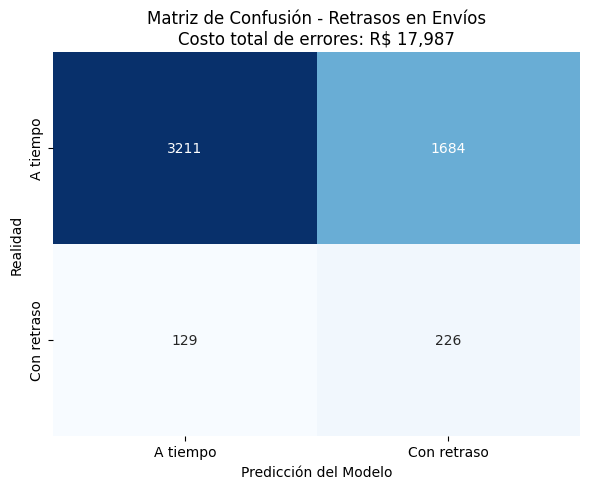

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Matriz de confusión sobre validación (mismas variables de las Actividades 1 y 2)
cm = confusion_matrix(y_valid, pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['A tiempo', 'Con retraso'],
            yticklabels=['A tiempo', 'Con retraso'])
plt.title(f'Matriz de Confusión - Retrasos en Envíos\nCosto total de errores: R$ {costo_fp_fn:,.0f}')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Realidad')
plt.tight_layout()
plt.show()

**Lectura:** el modelo acierta 226 retrasos (verdaderos positivos) y deja pasar 129 (falsos negativos), pero genera 1.684 falsas alarmas. Esa cifra de falsos positivos explica la mayor parte del costo total (R$ 13.472 de R$ 17.987).

### 2. Curva Precision-Recall (Ajuste de Umbral)

Ilustra la relación de compromiso (*trade-off*) entre la Precisión (cuántos de los pedidos alertados como tardíos realmente lo fueron) y el Recall (qué porcentaje del total de pedidos retrasados logró capturar el modelo) a medida que varía el umbral de decisión.

* **Objetivo:** Visualizar el compromiso entre Precision y Recall y comparar el modelo con la línea base. El umbral óptimo por costo se calculará en la semana 13.

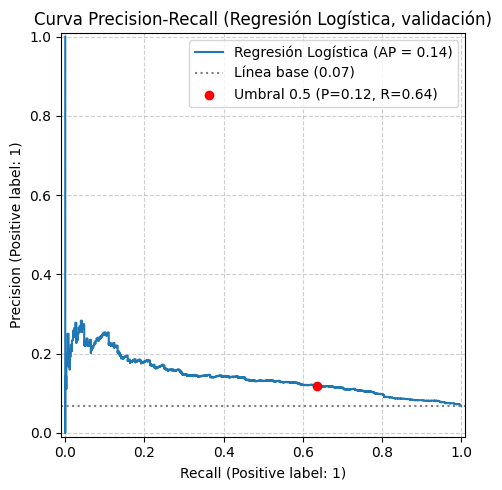

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay

fig, ax = plt.subplots(figsize=(7, 5))
PrecisionRecallDisplay.from_estimator(modelo, X_valid, y_valid, ax=ax,
                                      name='Regresión Logística')

# Línea base: proporción de pedidos tardíos (un modelo aleatorio rinde igual a esto)
ax.axhline(y_valid.mean(), color='gray', linestyle=':',
           label=f'Línea base ({y_valid.mean():.2f})')

# Punto de operación actual (umbral 0.5): Precision y Recall en validación
ax.scatter(medidas['recall'], medidas['precision'], color='red', zorder=5,
           label=f"Umbral 0.5 (P={medidas['precision']:.2f}, R={medidas['recall']:.2f})")

ax.set_title('Curva Precision-Recall (Regresión Logística, validación)')
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()

**Lectura:** la curva queda claramente por encima de la línea base (0.07), con un AP de 0.140, aproximadamente el doble de la prevalencia de retrasos. Con el umbral por defecto, el modelo opera en Precision 0.12 y Recall 0.64: captura la mayoría de los retrasos, pero con muchas falsas alarmas.

### 3. Distribución de Errores en Días (Regresión - MAE)

Representa mediante un histograma con estimación de densidad (KDE) la magnitud del error absoluto ($|\text{Real} - \text{Predicción}|$) expresado en días para el modelo de regresión.

* **Objetivo:** Analizar el comportamiento del error puntual respecto al **MAE del modelo de 5,21 días**, verificando la concentración de las desviaciones y detectando posibles valores atípicos (*outliers*) en las entregas.

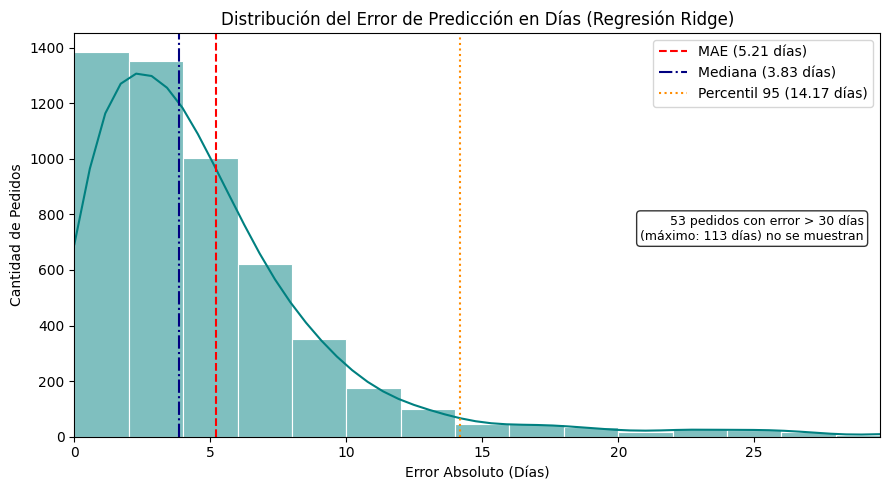

MAE                : 5.21 días
Mediana del error  : 3.83 días
Error <= 7 días    : 78.1 %
Percentil 95       : 14.17 días
Error máximo       : 112.94 días


In [27]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Error absoluto en días (regresión Ridge de la sección 5)
errores = np.abs(valid['dias_entrega'].values - pred_dias)

# Estadísticas del error (las mismas cifras se citan en la interpretación)
mediana = np.median(errores)
p95 = np.percentile(errores, 95)
maximo = errores.max()
pct_hasta_7 = 100 * (errores <= 7).mean()

# El eje X se recorta en el percentil 99 para que la cola larga no aplaste el histograma
limite_x = np.percentile(errores, 99)
fuera = int((errores > limite_x).sum())

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(errores, bins=np.arange(0, limite_x + 2, 2), kde=True,
             kde_kws={'cut': 0}, color='teal', edgecolor='white', ax=ax)

# MAE (se usa el valor calculado en la sección 5), mediana y percentil 95
ax.axvline(mae, color='red', linestyle='--', label=f'MAE ({mae:.2f} días)')
ax.axvline(mediana, color='navy', linestyle='-.', label=f'Mediana ({mediana:.2f} días)')
ax.axvline(p95, color='darkorange', linestyle=':', label=f'Percentil 95 ({p95:.2f} días)')

ax.set_xlim(0, limite_x)
ax.set_title('Distribución del Error de Predicción en Días (Regresión Ridge)')
ax.set_xlabel('Error Absoluto (Días)')
ax.set_ylabel('Cantidad de Pedidos')
ax.legend()

# Aviso de los casos que quedan fuera del recorte del eje
ax.text(0.98, 0.55, f'{fuera} pedidos con error > {limite_x:.0f} días\n'
                    f'(máximo: {maximo:.0f} días) no se muestran',
        transform=ax.transAxes, ha='right', va='top', fontsize=9,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()

print(f'MAE                : {mae:.2f} días')
print(f'Mediana del error  : {mediana:.2f} días')
print(f'Error <= 7 días    : {pct_hasta_7:.1f} %')
print(f'Percentil 95       : {p95:.2f} días')
print(f'Error máximo       : {maximo:.2f} días')

**Lectura:** el MAE es de 5,21 días, pero la distribución del error es muy asimétrica: la mediana es de 3,83 días y el 78,1 % de los pedidos se predice con un error de 7 días o menos. Existe una cola larga de casos atípicos, con un error máximo de 112,94 días y un percentil 95 de 14,17 días, que eleva el MAE por encima del error típico. Esto indica que el modelo es razonablemente preciso para la mayoría de los pedidos, pero falla de forma grande en unos pocos, probablemente entregas excepcionalmente demoradas que las variables disponibles no anticipan.